In [109]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def loadData(folder, label, image_size=(32, 32)):
    data = []
    for filename in os.listdir(folder):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            path = os.path.join(folder, filename)
            try:
                img = Image.open(path).convert('RGB')
                img = img.resize(image_size)
                img_array = np.array(img).flatten() / 255.0
                data.append((img_array, label))
            except Exception as e:
                print(f"Eroare la {filename}: {e}")
    return data



normalData = loadData('photos', label=0)
sepiaData = loadData('photos_sepia', label=1)

allData = normalData + sepiaData
np.random.shuffle(allData)

inputs = [x[0] for x in allData]
outputs = [x[1] for x in allData]



In [110]:
def splitData(inputs_data, outputs_data):
    np.random.seed(5)
    indexes = [i for i in range(len(inputs_data))]
    trainSample = np.random.choice(indexes, int(0.8 * len(inputs_data)), replace = False)
    testSample = [i for i in indexes  if not i in trainSample]

    trainInputs = [inputs_data[i] for i in trainSample]
    trainOutputs = [outputs_data[i] for i in trainSample]
    testInputs = [inputs_data[i] for i in testSample]
    testOutputs = [outputs_data[i] for i in testSample]

    return trainInputs, trainOutputs, testInputs, testOutputs

trainInputs, trainOutputs, testInputs, testOutputs = splitData(inputs, outputs)
print(f"Train set: {len(trainInputs)} imagini")
print(f"Test set: {len(testOutputs)} imagini")


Train set: 139 imagini
Test set: 35 imagini


Accuracy:  0.8
Precision normal:  0.8235294117647058
Precision sepia:  0.7777777777777778
Recall normal:  0.7777777777777778
Recall sepia:  0.8235294117647058


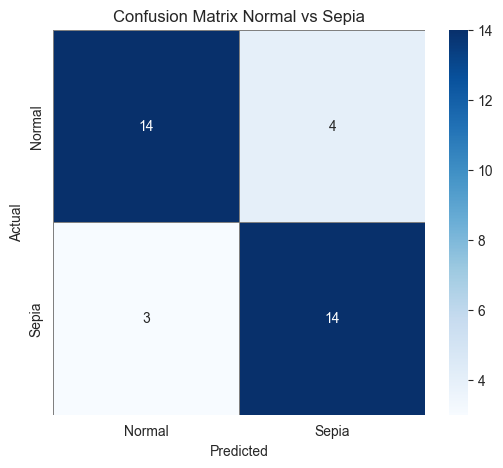

In [111]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import seaborn as sns

classifier = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation='relu',
    solver='sgd',
    learning_rate_init=0.01,
    max_iter=2000,
    random_state=42
)

classifier.fit(trainInputs, trainOutputs)

predictedLabels = classifier.predict(testInputs)

acc = accuracy_score(testOutputs, predictedLabels)
prec = precision_score(testOutputs, predictedLabels, average=None, zero_division=0)
recall = recall_score(testOutputs, predictedLabels, average=None, zero_division=0)
print("Accuracy: ", acc)
print("Precision normal: ", prec[0])
print("Precision sepia: ", prec[1])
print("Recall normal: ", recall[0])
print("Recall sepia: ", recall[1])


cm = confusion_matrix(testOutputs, predictedLabels)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
    xticklabels=["Normal", "Sepia"],
    yticklabels=["Normal", "Sepia"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Normal vs Sepia")
plt.show()






Accuracy:  0.7714285714285715
Precision normal:  0.7777777777777778
Precision sepia:  0.7647058823529411
Recall normal:  0.7777777777777778
Recall sepia:  0.7647058823529411


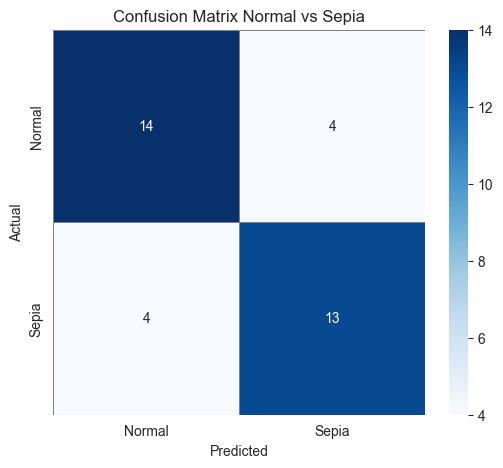

In [112]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import seaborn as sns

classifier = MLPClassifier(
    hidden_layer_sizes=(10, 10, 10),
    activation='relu',
    solver='sgd',
    learning_rate_init=0.001,
    max_iter=2000,
    random_state=42
)

classifier.fit(trainInputs, trainOutputs)

predictedLabels = classifier.predict(testInputs)

acc = accuracy_score(testOutputs, predictedLabels)
prec = precision_score(testOutputs, predictedLabels, average=None, zero_division=0)
recall = recall_score(testOutputs, predictedLabels, average=None, zero_division=0)
print("Accuracy: ", acc)
print("Precision normal: ", prec[0])
print("Precision sepia: ", prec[1])
print("Recall normal: ", recall[0])
print("Recall sepia: ", recall[1])


cm = confusion_matrix(testOutputs, predictedLabels)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
    xticklabels=["Normal", "Sepia"],
    yticklabels=["Normal", "Sepia"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Normal vs Sepia")
plt.show()






Accuracy:  0.5142857142857142
Precision normal:  0.5142857142857142
Precision sepia:  0.0
Recall normal:  1.0
Recall sepia:  0.0


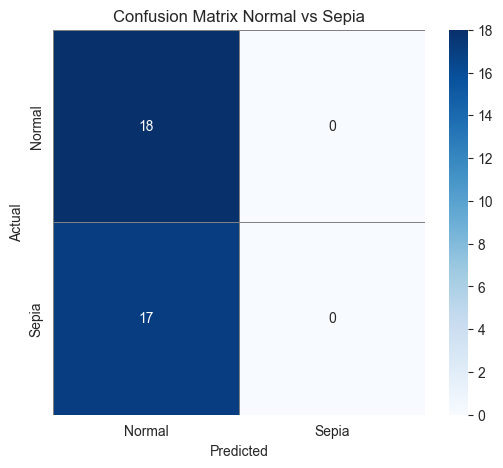

In [113]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import seaborn as sns

classifier = MLPClassifier(
    hidden_layer_sizes=(5,),
    activation='relu',
    solver='sgd',
    learning_rate_init=0.001,
    max_iter=2000,
    random_state=42
)

classifier.fit(trainInputs, trainOutputs)

predictedLabels = classifier.predict(testInputs)

acc = accuracy_score(testOutputs, predictedLabels)
prec = precision_score(testOutputs, predictedLabels, average=None, zero_division=0)
recall = recall_score(testOutputs, predictedLabels, average=None, zero_division=0)
print("Accuracy: ", acc)
print("Precision normal: ", prec[0])
print("Precision sepia: ", prec[1])
print("Recall normal: ", recall[0])
print("Recall sepia: ", recall[1])


cm = confusion_matrix(testOutputs, predictedLabels)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
    xticklabels=["Normal", "Sepia"],
    yticklabels=["Normal", "Sepia"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Normal vs Sepia")
plt.show()




